In [1]:
!pip install -q -U bitsandbytes accelerate datasets gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 9.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
import os
import re
import json
import random
import time

import joblib
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), "Use Runtime > Change runtime type > T4 GPU"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/brain_sentinel"
except Exception:
    DATA_DIR = "brain_sentinel_data"
os.makedirs(DATA_DIR, exist_ok=True)

MODEL_NAME = "Qwen/Qwen3-8B"
TRAIN_QUESTIONS = 1500   # first 500 are reused from the saved cache; set back to 500 to skip new generation
TEST_FRACTION = 0.2
MAX_NEW_TOKENS = 40
CHECKPOINT_TOKENS = [4, 8, 16, 32]
UNSURE_MARGIN = 0.10

GENERATION_PATH = os.path.join(DATA_DIR, "generations.csv")
TRAJECTORY_PATH = os.path.join(DATA_DIR, "trajectories.csv")
DETECTOR_PATH = os.path.join(DATA_DIR, "detectors.joblib")
REPORT_PATH = os.path.join(DATA_DIR, "checkpoint_report.csv")
ABLATION_PATH = os.path.join(DATA_DIR, "ablation_report.csv")
VECTORS_PATH = os.path.join(DATA_DIR, "hidden_vectors.joblib")
LENGTH_PATH = os.path.join(DATA_DIR, "length_baseline.json")

SYSTEM_PROMPT = (
    "Answer the question in one complete sentence. "
    "If you are not sure, say that you do not know."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Data directory:", DATA_DIR)

Mounted at /content/drive
GPU: Tesla T4
Data directory: /content/drive/MyDrive/brain_sentinel


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quantization,
    device_map="auto",
)
model.eval()
for parameter in model.parameters():
    parameter.requires_grad = False

N_LAYERS = model.config.num_hidden_layers
LAYERS = [N_LAYERS // 3, 4 * N_LAYERS // 9, 5 * N_LAYERS // 9, 2 * N_LAYERS // 3]

eos = model.generation_config.eos_token_id
STOP_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
STOP_IDS.add(tokenizer.eos_token_id)
STOP_IDS.discard(None)

print("Model:", MODEL_NAME)
print("Transformer layers:", N_LAYERS, "| monitored layers:", LAYERS)
print("GPU memory used: %.1f GB" % (torch.cuda.memory_allocated() / 1024 ** 3))

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model: Qwen/Qwen3-8B
Transformer layers: 36 | monitored layers: [12, 16, 20, 24]
GPU memory used: 6.0 GB


In [4]:
def build_chat_prompt(question):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )


def stream_answer(question, max_new_tokens=MAX_NEW_TOKENS, with_vectors=False):
    prompt = build_chat_prompt(question)
    step_input = tokenizer(
        prompt, return_tensors="pt", add_special_tokens=False
    )["input_ids"].to(model.device)
    past = None
    previous = {layer: None for layer in LAYERS}

    for step in range(1, max_new_tokens + 1):
        with torch.no_grad():
            outputs = model(
                input_ids=step_input,
                past_key_values=past,
                use_cache=True,
                output_hidden_states=True,
                return_dict=True,
            )
        past = outputs.past_key_values

        probs = torch.softmax(outputs.logits[:, -1, :].float(), dim=-1)
        next_id = torch.argmax(probs, dim=-1, keepdim=True)
        token_id = next_id.item()
        entropy = -(probs * torch.log(probs + 1e-12)).sum().item()

        row = {
            "step": step,
            "token_id": token_id,
            "token": tokenizer.decode([token_id]),
            "token_probability": probs[0, token_id].item(),
            "entropy": entropy,
            "normalized_entropy": entropy / float(np.log(probs.shape[-1])),
        }

        for layer in LAYERS:
            hidden = outputs.hidden_states[layer][0, -1, :].float()
            row[f"L{layer}_norm"] = torch.norm(hidden).item()
            if previous[layer] is None:
                row[f"L{layer}_delta"] = np.nan
                row[f"L{layer}_cosine"] = np.nan
            else:
                row[f"L{layer}_delta"] = torch.norm(hidden - previous[layer]).item()
                row[f"L{layer}_cosine"] = torch.nn.functional.cosine_similarity(
                    hidden.unsqueeze(0), previous[layer].unsqueeze(0)
                ).item()
            previous[layer] = hidden.detach().clone()
            if with_vectors:
                row.setdefault("_vec", {})[layer] = hidden.half().cpu().numpy()

        yield row

        if token_id in STOP_IDS:
            break
        step_input = next_id


test_rows = list(stream_answer("What is the capital of France?"))
print(tokenizer.decode([r["token_id"] for r in test_rows], skip_special_tokens=True))
print("Tokens:", len(test_rows))

The capital of France is Paris.
Tokens: 8


In [5]:
HIDDEN_BASE = [f"L{layer}_{kind}" for layer in LAYERS for kind in ("norm", "delta", "cosine")]
UNCERTAINTY_BASE = ["token_probability", "entropy", "normalized_entropy"]
STATS = ("mean", "std", "min", "max")


def expand(bases):
    return [f"{base}_{stat}" for base in bases for stat in STATS]


FEATURE_GROUPS = {
    "hidden-state only": expand(HIDDEN_BASE),
    "uncertainty only": expand(UNCERTAINTY_BASE),
    "combined": expand(HIDDEN_BASE + UNCERTAINTY_BASE),
}
FEATURE_COLUMNS = FEATURE_GROUPS["combined"]


def summarize(rows):
    frame = pd.DataFrame(rows)
    features = {}
    for base in HIDDEN_BASE + UNCERTAINTY_BASE:
        values = pd.to_numeric(frame[base], errors="coerce").dropna()
        features[f"{base}_mean"] = values.mean()
        features[f"{base}_std"] = values.std()
        features[f"{base}_min"] = values.min()
        features[f"{base}_max"] = values.max()
    return features


def make_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)),
    ])


def normalize(text):
    text = str(text).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


ABSTAIN_PHRASES = ["do not know", "don t know", "not sure", "unsure", "cannot answer", "no information"]


def label_answer(answer, aliases):
    cleaned = f" {normalize(answer)} "
    for alias in aliases:
        alias = normalize(alias)
        if alias and f" {alias} " in cleaned:
            return "CORRECT"
    if any(phrase in cleaned for phrase in ABSTAIN_PHRASES):
        return "ABSTAIN"
    return "INCORRECT"

In [6]:
def load_trivia(count):
    try:
        dataset = load_dataset("mandarjoshi/trivia_qa", "rc.nocontext", split="validation")
    except Exception:
        dataset = load_dataset("trivia_qa", "rc.nocontext", split="validation")
    dataset = dataset.shuffle(seed=SEED).select(range(count))
    records = []
    for i, item in enumerate(dataset):
        answer = item["answer"]
        aliases = list(answer.get("aliases", [])) + [answer.get("value", "")]
        records.append({
            "sample_id": f"TV_{i:04d}",
            "question": item["question"],
            "aliases": json.dumps(aliases),
        })
    return pd.DataFrame(records)


def generate_corpus(questions, save_every=20):
    if os.path.exists(GENERATION_PATH) and os.path.exists(TRAJECTORY_PATH):
        generations = pd.read_csv(GENERATION_PATH).to_dict("records")
        trajectories = [pd.read_csv(TRAJECTORY_PATH)]
    else:
        generations, trajectories = [], []

    done = {record["sample_id"] for record in generations}
    started = time.time()
    new_count = 0

    def persist():
        pd.DataFrame(generations).to_csv(GENERATION_PATH, index=False)
        pd.concat(trajectories, ignore_index=True).to_csv(TRAJECTORY_PATH, index=False)

    for _, row in questions.iterrows():
        if row["sample_id"] in done:
            continue
        rows = list(stream_answer(row["question"]))
        answer = tokenizer.decode(
            [r["token_id"] for r in rows], skip_special_tokens=True
        ).strip()
        label = label_answer(answer, json.loads(row["aliases"]))

        frame = pd.DataFrame(rows)
        frame["sample_id"] = row["sample_id"]
        trajectories.append(frame)
        generations.append({
            "sample_id": row["sample_id"],
            "question": row["question"],
            "answer": answer,
            "aliases": row["aliases"],
            "label": label,
        })
        new_count += 1

        if new_count % save_every == 0:
            persist()
            rate = new_count / max(time.time() - started, 1)
            print(f"{len(generations)}/{len(questions)} done ({rate:.2f} answers/sec)")

    persist()
    return pd.DataFrame(generations), pd.concat(trajectories, ignore_index=True)


question_df = load_trivia(TRAIN_QUESTIONS)
generation_df, trajectory_df = generate_corpus(question_df)

labeled_df = generation_df[generation_df["label"].isin(["CORRECT", "INCORRECT"])].copy()
labeled_df["target"] = (labeled_df["label"] == "INCORRECT").astype(int)

print(generation_df["label"].value_counts())
print("Usable for detector training:", len(labeled_df))

README.md:   0%|          | 0.00/26.7k [00:00<?, ?B/s]

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

rc.nocontext/train-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 55.4MB            

rc.nocontext/train-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

rc.nocontext/validation-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 7.34MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/138384 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/17944 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/17210 [00:00<?, ? examples/s]

520/1500 done (0.41 answers/sec)
540/1500 done (0.41 answers/sec)
560/1500 done (0.35 answers/sec)
580/1500 done (0.36 answers/sec)
600/1500 done (0.37 answers/sec)
620/1500 done (0.37 answers/sec)
640/1500 done (0.37 answers/sec)
660/1500 done (0.38 answers/sec)
680/1500 done (0.39 answers/sec)
700/1500 done (0.39 answers/sec)
720/1500 done (0.39 answers/sec)
740/1500 done (0.39 answers/sec)
760/1500 done (0.39 answers/sec)
780/1500 done (0.39 answers/sec)
800/1500 done (0.40 answers/sec)
820/1500 done (0.40 answers/sec)
840/1500 done (0.40 answers/sec)
860/1500 done (0.39 answers/sec)
880/1500 done (0.39 answers/sec)
900/1500 done (0.39 answers/sec)
920/1500 done (0.39 answers/sec)
940/1500 done (0.39 answers/sec)
960/1500 done (0.39 answers/sec)
980/1500 done (0.40 answers/sec)
1000/1500 done (0.40 answers/sec)
1020/1500 done (0.40 answers/sec)
1040/1500 done (0.40 answers/sec)
1060/1500 done (0.40 answers/sec)
1080/1500 done (0.40 answers/sec)
1100/1500 done (0.40 answers/sec)
1120

In [7]:
def extract_vectors(question, token_ids):
    """Teacher-forced pass over a saved answer. Returns the mean hidden vector over the first k steps
    (k = each checkpoint) at each monitored layer, at exactly the positions the streaming monitor reads:
    the last prompt token, then every answer token except the final one."""
    prompt_ids = tokenizer(build_chat_prompt(question), return_tensors="pt", add_special_tokens=False)["input_ids"]
    steps = len(token_ids)
    if steps > 1:
        prompt_ids = torch.cat([prompt_ids, torch.tensor([token_ids[:-1]], dtype=torch.long)], dim=1)
    with torch.no_grad():
        out = model(input_ids=prompt_ids.to(model.device), output_hidden_states=True, return_dict=True)
    result = {}
    for layer in LAYERS:
        h = out.hidden_states[layer][0, -steps:].float()
        for k in CHECKPOINT_TOKENS:
            result[(k, layer)] = h[:k].mean(0).cpu().numpy().astype(np.float16)
    return result


def load_vectors():
    if os.path.exists(VECTORS_PATH):
        saved = joblib.load(VECTORS_PATH)
        if (saved["model_name"], saved["layers"], saved["checkpoints"]) == (MODEL_NAME, LAYERS, CHECKPOINT_TOKENS):
            return saved["vectors"]
    return {}


def save_vectors(vectors):
    joblib.dump({"model_name": MODEL_NAME, "layers": LAYERS, "checkpoints": CHECKPOINT_TOKENS, "vectors": vectors}, VECTORS_PATH)


VECTORS = load_vectors()
token_ids_by_sample = {sid: g.sort_values("step")["token_id"].tolist() for sid, g in trajectory_df.groupby("sample_id")}
question_by_sample = question_df.set_index("sample_id")["question"].to_dict()

todo = [sid for sid in labeled_df["sample_id"] if sid not in VECTORS]
for n, sid in enumerate(todo, start=1):
    VECTORS[sid] = extract_vectors(question_by_sample[sid], token_ids_by_sample[sid])
    if n % 100 == 0:
        save_vectors(VECTORS)
        print(f"hidden vectors: {n}/{len(todo)}")
save_vectors(VECTORS)
print(f"Hidden vectors ready for {len(VECTORS)} answers")

hidden vectors: 100/1496
hidden vectors: 200/1496
hidden vectors: 300/1496
hidden vectors: 400/1496
hidden vectors: 500/1496
hidden vectors: 600/1496
hidden vectors: 700/1496
hidden vectors: 800/1496
hidden vectors: 900/1496
hidden vectors: 1000/1496
hidden vectors: 1100/1496
hidden vectors: 1200/1496
hidden vectors: 1300/1496
hidden vectors: 1400/1496
Hidden vectors ready for 1496 answers


In [8]:
PROBE_KINDS = ["uncertainty only", "hidden-state only", "combined", "hidden-vector", "fusion"]
VECTOR_KINDS = ("hidden-vector", "fusion")


def checkpoint_dataset(trajectories, tokens):
    rows = {}
    for sample_id, group in trajectories.groupby("sample_id"):
        rows[sample_id] = summarize(group.sort_values("step").iloc[:tokens])
    return pd.DataFrame.from_dict(rows, orient="index")


def make_model(kind):
    if kind in FEATURE_GROUPS or kind == "length":
        return make_pipeline()
    if kind == "hidden-vector":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(C=0.005, max_iter=3000, random_state=SEED)),
        ])
    n_sc = len(FEATURE_COLUMNS)
    pre = ColumnTransformer([
        ("sc", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                         ("scaler", StandardScaler())]), list(range(n_sc))),
        ("vec", Pipeline([("scaler", StandardScaler()),
                          ("pca", PCA(n_components=32, random_state=SEED))]), slice(n_sc, None)),
    ])
    return Pipeline([("pre", pre), ("classifier", LogisticRegression(C=0.1, max_iter=2000, random_state=SEED))])


def cross_val_oof(kind, X, y, folds):
    oof = np.zeros(len(y))
    fold_auc = []
    for train_idx, test_idx in folds.split(X, y):
        fitted = make_model(kind).fit(X[train_idx], y[train_idx])
        probabilities = fitted.predict_proba(X[test_idx])[:, 1]
        oof[test_idx] = probabilities
        fold_auc.append(roc_auc_score(y[test_idx], probabilities))
    return oof, fold_auc


def youden_threshold(y, scores):
    fpr, tpr, thresholds = roc_curve(y, scores)
    return float(thresholds[np.argmax(tpr - fpr)])


def threshold_metrics(y, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    return {
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "wrong_caught_recall": recall_score(y, predictions, zero_division=0),
        "flag_precision": precision_score(y, predictions, zero_division=0),
        "false_alarm_rate": float(((predictions == 1) & (y == 0)).sum() / max((y == 0).sum(), 1)),
    }


def train_detectors(trajectories, labeled):
    labels = labeled.set_index("sample_id")["target"]
    subset = trajectories[trajectories["sample_id"].isin(labels.index)]
    ids = labels.index.to_numpy()
    y_all = labels.to_numpy()
    train_ids, test_ids = train_test_split(ids, test_size=TEST_FRACTION, stratify=y_all, random_state=SEED)
    y_tr, y_te = labels.loc[train_ids].to_numpy(), labels.loc[test_ids].to_numpy()
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scalar = {k: checkpoint_dataset(subset, k) for k in CHECKPOINT_TOKENS}

    def features(kind, sample_ids, k, layer):
        sc = scalar[k].loc[sample_ids]
        if kind in FEATURE_GROUPS:
            return sc[FEATURE_GROUPS[kind]].to_numpy(dtype=float)
        vec = np.stack([VECTORS[s][(k, layer)] for s in sample_ids]).astype(np.float32)
        if kind == "hidden-vector":
            return vec
        return np.hstack([sc[FEATURE_COLUMNS].to_numpy(dtype=float), vec])

    length = subset.groupby("sample_id").size().loc[ids].to_numpy(dtype=float).reshape(-1, 1)
    length_oof, length_folds = cross_val_oof("length", length, y_all, folds)
    length_auc = float(np.mean(length_folds))


    best_layer = {}
    for k in CHECKPOINT_TOKENS:
        scores = {}
        for layer in LAYERS:
            _, fold_auc = cross_val_oof("hidden-vector", features("hidden-vector", train_ids, k, layer), y_tr, folds)
            scores[layer] = float(np.mean(fold_auc))
        best_layer[k] = max(scores, key=scores.get)

    rows = []
    for k in CHECKPOINT_TOKENS:
        layer = best_layer[k]
        for kind in PROBE_KINDS:
            X_tr, X_te = features(kind, train_ids, k, layer), features(kind, test_ids, k, layer)
            oof, fold_auc = cross_val_oof(kind, X_tr, y_tr, folds)
            threshold = youden_threshold(y_tr, oof)
            test_scores = make_model(kind).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
            row = {
                "tokens": k,
                "features": kind,
                "layer": layer if kind in VECTOR_KINDS else np.nan,
                "cv_auc": float(np.mean(fold_auc)),
                "cv_std": float(np.std(fold_auc, ddof=1)),
                "test_auc": roc_auc_score(y_te, test_scores),
                "threshold": threshold,
            }
            row.update(threshold_metrics(y_te, test_scores, threshold))
            rows.append(row)
    ablation = pd.DataFrame(rows)

    detectors, report = {}, []
    for k in CHECKPOINT_TOKENS:
        candidates = ablation[(ablation["tokens"] == k) & ablation["features"].isin(["combined", "fusion"])]
        kind = candidates.sort_values("cv_auc").iloc[-1]["features"]
        layer = best_layer[k]
        X_all = features(kind, ids, k, layer)
        oof, _ = cross_val_oof(kind, X_all, y_all, folds)
        detectors[k] = {
            "model": make_model(kind).fit(X_all, y_all),
            "threshold": youden_threshold(y_all, oof),
            "kind": kind,
            "layer": int(layer),
        }
        chosen = ablation[(ablation["tokens"] == k) & (ablation["features"] == kind)].iloc[0].to_dict()
        chosen.update({"samples": len(ids), "wrong_answers": int(y_all.sum())})
        report.append(chosen)

    return detectors, pd.DataFrame(report), ablation, length_auc


def load_saved_detectors():
    if not os.path.exists(DETECTOR_PATH):
        return None
    saved = joblib.load(DETECTOR_PATH)
    if saved.get("version") == 2 and saved["model_name"] == MODEL_NAME and saved["layers"] == LAYERS \
            and saved["n_samples"] == len(labeled_df):
        return saved["detectors"]
    return None


detectors = load_saved_detectors()
if detectors is None:
    detectors, report_df, ablation_df, length_auc = train_detectors(trajectory_df, labeled_df)
    joblib.dump(
        {
            "version": 2,
            "model_name": MODEL_NAME,
            "layers": LAYERS,
            "checkpoints": CHECKPOINT_TOKENS,
            "n_samples": len(labeled_df),
            "detectors": detectors,
        },
        DETECTOR_PATH,
    )
    report_df.to_csv(REPORT_PATH, index=False)
    ablation_df.to_csv(ABLATION_PATH, index=False)
    json.dump({"length_only_cv_auc": length_auc}, open(LENGTH_PATH, "w"))
    print("Detectors trained:", {k: v["kind"] for k, v in detectors.items()})
else:
    print("Loaded saved detectors:", sorted(detectors))

Detectors trained: {4: 'fusion', 8: 'fusion', 16: 'fusion', 32: 'fusion'}


In [9]:
def classify(risk, threshold):
    if risk >= threshold:
        return "LIKELY WRONG"
    if risk >= threshold - UNSURE_MARGIN:
        return "UNSURE"
    return "LIKELY RIGHT"


def score_prefix(rows, key):
    detector = detectors[key]
    scalar = pd.DataFrame([summarize(rows[:key])])[FEATURE_COLUMNS].to_numpy(dtype=float)
    if detector["kind"] == "fusion":
        vector = np.mean([r["_vec"][detector["layer"]] for r in rows[:key]], axis=0).astype(np.float32)[None, :]
        features = np.hstack([scalar, vector])
    else:
        features = scalar
    risk = float(detector["model"].predict_proba(features)[0, 1])
    return {
        "checkpoint_tokens": key,
        "tokens_seen": min(len(rows), key),
        "risk_score": risk,
        "threshold": detector["threshold"],
        "status": classify(risk, detector["threshold"]),
    }


def monitor_stream(question, stop_on_warning=False):
    rows = []
    checks = []
    stopped = False

    for row in stream_answer(question, with_vectors=True):
        rows.append(row)
        answer = tokenizer.decode(
            [r["token_id"] for r in rows], skip_special_tokens=True
        ).strip()
        yield {"event": "token", "answer": answer}

        if len(rows) in detectors:
            check = score_prefix(rows, len(rows))
            checks.append(check)
            yield {"event": "checkpoint", "check": check}
            if stop_on_warning and check["status"] == "LIKELY WRONG":
                stopped = True
                break

    if rows and not stopped and len(rows) not in detectors:
        key = next((k for k in sorted(detectors) if k >= len(rows)), max(detectors))
        check = score_prefix(rows, key)
        checks.append(check)
        yield {"event": "checkpoint", "check": check}

    answer = tokenizer.decode(
        [r["token_id"] for r in rows], skip_special_tokens=True
    ).strip()
    first_warning = next(
        (c["tokens_seen"] for c in checks if c["status"] == "LIKELY WRONG"), None
    )
    yield {
        "event": "final",
        "answer": answer,
        "checks": checks,
        "verdict": checks[-1]["status"] if checks else "NO ANSWER",
        "first_warning_tokens": first_warning,
        "stopped_early": stopped,
    }


def verdict_message(final):
    if final["verdict"] == "NO ANSWER":
        return "The model did not produce an answer."
    last = final["checks"][-1]
    detail = f"risk {last['risk_score']:.3f} at {last['tokens_seen']} tokens"
    early = final["first_warning_tokens"]

    if final["stopped_early"]:
        return f"LIKELY WRONG: generation stopped at {early} tokens after an early warning ({detail})."
    if final["verdict"] == "LIKELY WRONG":
        return f"LIKELY WRONG: first warning at {early} tokens ({detail}). Do not trust this answer."
    if final["verdict"] == "UNSURE":
        return f"UNSURE: close to the warning threshold ({detail}). Double-check this answer."
    if early is not None:
        return f"LIKELY RIGHT at the end ({detail}), but an early warning was raised at {early} tokens. Double-check."
    return f"LIKELY RIGHT ({detail}). This is an experimental probe, not a fact check."

In [10]:
def run_terminal_chat(stop_on_warning=False):
    print("=" * 70)
    print("AI Brain Sentinel  |", MODEL_NAME)
    print("Type a question. Type 'exit' to quit.")
    print("=" * 70)
    while True:
        try:
            question = input("\nYou: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if question.lower() in ("exit", "quit"):
            break
        if not question:
            continue

        print("Model: ", end="", flush=True)
        printed = 0
        final = None
        for event in monitor_stream(question, stop_on_warning=stop_on_warning):
            if event["event"] == "token":
                text = event["answer"]
                if len(text) > printed:
                    print(text[printed:], end="", flush=True)
                    printed = len(text)
            elif event["event"] == "final":
                final = event
        print("\n\nCheckpoints:")
        for c in final["checks"]:
            print(
                f"  {c['checkpoint_tokens']:>2} tokens | risk {c['risk_score']:.3f} | "
                f"threshold {c['threshold']:.3f} | {c['status']}"
            )
        print("\n" + verdict_message(final))


def checks_markdown(checks):
    lines = [
        "| Checkpoint | Tokens seen | Risk | Threshold | Status |",
        "|---|---|---|---|---|",
    ]
    for c in checks:
        lines.append(
            f"| {c['checkpoint_tokens']} | {c['tokens_seen']} | "
            f"{c['risk_score']:.3f} | {c['threshold']:.3f} | {c['status']} |"
        )
    return "\n".join(lines)


def launch_ui(share=True):
    import gradio as gr

    def respond(question, stop_on_warning):
        question = (question or "").strip()
        if not question:
            yield "", "", "Type a question first."
            return
        answer, checks, status = "", [], "Generating..."
        for event in monitor_stream(question, stop_on_warning=stop_on_warning):
            if event["event"] == "token":
                answer = event["answer"]
            elif event["event"] == "checkpoint":
                checks.append(event["check"])
                status = f"Checkpoint {event['check']['checkpoint_tokens']}: {event['check']['status']}"
            elif event["event"] == "final":
                answer = event["answer"]
                status = verdict_message(event)
            yield answer, checks_markdown(checks) if checks else "", status

    with gr.Blocks(title="AI Brain Sentinel") as demo:
        gr.Markdown("# AI Brain Sentinel")
        gr.Markdown(f"`{MODEL_NAME}` answers; its own hidden states are checked at token checkpoints {CHECKPOINT_TOKENS}.")
        question = gr.Textbox(label="Your question", lines=2, placeholder="Who wrote Pride and Prejudice?")
        stop_box = gr.Checkbox(label="Stop generation at the first warning", value=False)
        ask = gr.Button("Ask", variant="primary")
        answer_box = gr.Textbox(label="Answer", lines=5, interactive=False)
        status_box = gr.Markdown()
        checks_box = gr.Markdown()
        ask.click(respond, [question, stop_box], [answer_box, checks_box, status_box])
        question.submit(respond, [question, stop_box], [answer_box, checks_box, status_box])

    demo.queue().launch(share=share, debug=False)

Held-out test ROC-AUC (20% of questions never used for any choice)
features  uncertainty only  hidden-state only  combined  hidden-vector  fusion
tokens                                                                        
4                    0.510              0.679     0.678          0.814   0.777
8                    0.545              0.694     0.701          0.803   0.800
16                   0.633              0.699     0.781          0.833   0.844
32                   0.816              0.730     0.834          0.857   0.888

Cross-validated ROC-AUC on the training split
features  uncertainty only  hidden-state only  combined  hidden-vector  fusion
tokens                                                                        
4                    0.600              0.695     0.708          0.815   0.797
8                    0.613              0.700     0.723          0.826   0.816
16                   0.689              0.742     0.796          0.846   0.841
32               

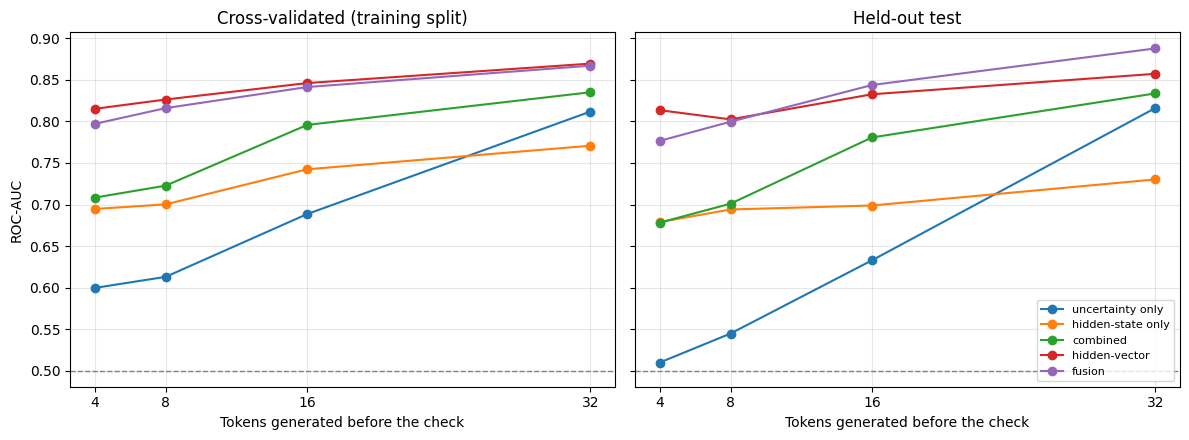

In [11]:
import matplotlib.pyplot as plt

report_df = pd.read_csv(REPORT_PATH)
ablation_df = pd.read_csv(ABLATION_PATH)
length_auc = json.load(open(LENGTH_PATH))["length_only_cv_auc"]

print("Held-out test ROC-AUC (20% of questions never used for any choice)")
print(ablation_df.pivot(index="tokens", columns="features", values="test_auc")[PROBE_KINDS].round(3).to_string())
print("\nCross-validated ROC-AUC on the training split")
print(ablation_df.pivot(index="tokens", columns="features", values="cv_auc")[PROBE_KINDS].round(3).to_string())
print(f"\nAnswer length alone (cross-validated ROC-AUC): {length_auc:.3f}")
print("\nDeployed detector, held-out test (threshold taken from the training split)")
print(report_df[["tokens", "features", "layer", "test_auc", "wrong_caught_recall", "flag_precision", "false_alarm_rate"]]
      .round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, column, title in [(axes[0], "cv_auc", "Cross-validated (training split)"), (axes[1], "test_auc", "Held-out test")]:
    for name in PROBE_KINDS:
        g = ablation_df[ablation_df["features"] == name].sort_values("tokens")
        ax.plot(g["tokens"], g[column], marker="o", label=name)
    ax.axhline(0.5, linestyle="--", linewidth=1, color="gray")
    ax.set_xticks(CHECKPOINT_TOKENS)
    ax.set_xlabel("Tokens generated before the check")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("ROC-AUC")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "checkpoint_auc.png"), dpi=300)
plt.show()

In [12]:
launch_ui(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5927cdb9c4696b165e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [13]:
run_terminal_chat()

AI Brain Sentinel  | Qwen/Qwen3-8B
Type a question. Type 'exit' to quit.
